# Retail Demand Forecasting — walkthrough

This notebook walks through the pipeline in `src/` step by step. All numbers come from executing the code below; the static results page (`index.html`) is generated by `python -m src.run_pipeline` from the same functions.

**Data:** ABS Retail Trade, Australia (cat. 8501.0, table 11), monthly turnover in A$ million by state and industry, via the `aus_retail` dataset in tidyverts/tsibbledata (pinned commit, checksum-verified).

In [1]:
import sys, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import pandas as pd
from src.data import load_raw, validate, prepare
from src.evaluate import backtest, series_metrics, summary, summary_by_origin, buffer_scenario, ORIGINS

## 1. Load and validate

In [2]:
raw = load_raw()
validate(raw)

{'rows': 64532,
 'series': 152,
 'first_month': '1982-04',
 'last_month': '2018-12'}

In [3]:
panel, info = prepare(raw)
print(info['series_kept'], 'of', info['leaf_series_total'], 'leaf series kept')
print('Dropped (discontinued or incomplete):', info['series_dropped'])
panel.head()

110 of 114 leaf series kept
Dropped (discontinued or incomplete): ['Queensland | Liquor retailing', 'Queensland | Other specialised food retailing', 'Tasmania | Liquor retailing', 'Tasmania | Other specialised food retailing']


,State,Industry,series_id,Month,Turnover,key
0,Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982-04-01,4.4,"Australian Capital Territory | Cafes, restaura..."
1,Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982-05-01,3.4,"Australian Capital Territory | Cafes, restaura..."
2,Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982-06-01,3.6,"Australian Capital Territory | Cafes, restaura..."
3,Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982-07-01,4.0,"Australian Capital Territory | Cafes, restaura..."
4,Australian Capital Territory,"Cafes, restaurants and catering services",A3349849A,1982-08-01,3.6,"Australian Capital Territory | Cafes, restaura..."


## 2. Exploratory analysis (data up to Dec 2015 only)

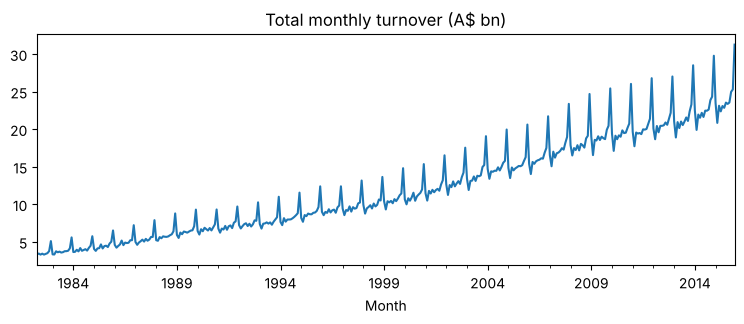

In [4]:
hist = panel[panel.Month <= ORIGINS[0]]
total = hist.groupby('Month').Turnover.sum()
ax = (total/1000).plot(figsize=(9,3), title='Total monthly turnover (A$ bn)')

In [5]:
annual = hist.assign(year=hist.Month.dt.year).query('year in [2005, 2015]').groupby(['Industry','year']).Turnover.sum().unstack()
((annual[2015]/annual[2005])**(1/10)-1).mul(100).sort_values().round(2).rename('CAGR 2005-2015 %')

Industry
Newspaper and book retailing                                        -2.52
Department stores                                                    1.22
Other specialised food retailing                                     1.54
Footwear and other personal accessory retailing                      2.56
Other recreational goods retailing                                   3.03
Electrical and electronic goods retailing                            3.04
Furniture, floor coverings, houseware and textile goods retailing    3.35
Clothing retailing                                                   4.12
Hardware, building and garden supplies retailing                     4.28
Takeaway food services                                               5.42
Supermarket and grocery stores                                       5.42
Other retailing n.e.c.                                               5.74
Liquor retailing                                                     5.92
Pharmaceutical, cosmetic and 

## 3. Rolling-origin backtest

Three origins (Dec 2015/2016/2017), 12-month horizon, models see only data up to the origin. Takes about a minute.

In [6]:
bt = backtest(panel)
sm = series_metrics(bt)
summary(sm).round(3)

,model,mean_MASE,median_MASE,median_MAPE_pct,share_beating_baseline_pct
0,Seasonal naive,1.212,1.013,5.762,NaN
1,ETS,1.058,0.893,4.841,62.424
2,Global GBM,1.119,0.964,5.076,57.576


In [7]:
summary_by_origin(sm).round(3)

model,Seasonal naive,ETS,Global GBM
test_year,,,
2016,1.348,1.135,1.172
2017,1.126,1.020,1.161
2018,1.163,1.019,1.023


## 4. Planning-buffer scenario

Not an inventory model: the data has no stock, units, lead times or costs. Buffers are sized from 2016–2017 ETS errors and checked against 2018.

In [8]:
buffer_scenario(bt, 'ETS').round(2)

,target_coverage_pct,realised_coverage_2018_pct,median_buffer_pct_of_forecast
0,80.0,76.36,4.07
1,90.0,82.42,5.99
2,95.0,87.65,8.04


## 5. Limitations

- Turnover in current dollars mixes price and volume.
- Three test years only; data ends in 2018.
- 24 errors per series is a small sample for tail quantiles.
- No exogenous drivers.